In [2]:
import pandas as pd
import numpy as np
import os
import re
from plotnine import *
from eval_plot_utils import parse_yml_pred,output_evaluation_outputs

In [3]:
collected_data = []
thesis_pre_data = []

## Evaluation on a subset of v2 data across multiple models - V2 Test

In [4]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

FileNotFoundError: [Errno 2] No such file or directory: '/ksi_ml/data/pairs_aug_v2.csv'

In [ ]:
pred_range = pd.read_csv('/ksi_ml/data/splits_v2/test.csv')
pred_range.columns = ['kinase_domain_seq','substrate_seq_15aa','label']

# pred_range = pd.read_csv('/ksi_ml/data/pairs_aug_v2_dark.csv').iloc[:,1:].drop_duplicates().loc[:,['kinase_domain_seq','substrate_seq_15aa','label']]

In [ ]:
pairs_pred = pd.merge(pairs_pred,pred_range).drop_duplicates()

In [ ]:
pairs_pred.head()

In [ ]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_v2.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

In [ ]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_v2.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [ ]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__db_lysate__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__db_lysate__53ceb023016e.pkl').drop_duplicates()

In [ ]:
tape_struct_db_lysate_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct/bert_struct_eval_pairs_db_lysate.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_pred = tape_struct_db_lysate_pred.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_pred.columns = ['kinase_seq','substrate_seq','probs']

In [5]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

NameError: name 'pairs_pred' is not defined

In [ ]:
esmt12_frozen = pd.read_csv('./eval_outputs/exp_esmt12_frozen_v2__pairs_v2.csv').iloc[:,1:]
esmt12_frozen = esmt12_frozen.iloc[:,[0,1,4]]
esmt12_frozen.columns = ['kinase_seq','substrate_seq','probs']

In [6]:
esmt12_noseq = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__db_lysate__2b97b6229963.pkl').drop_duplicates()
# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-CONCAT':esmt12_noseq.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-FROZEN':esmt12_frozen.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

pairs_pred = pairs_pred

FileNotFoundError: [Errno 2] No such file or directory: '/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__db_lysate__2b97b6229963.pkl'

In [ ]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [7]:

metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

NameError: name 'pairs_pred' is not defined

In [8]:
p2 = p2+ scale_y_continuous(limits=(0, 1))

NameError: name 'p2' is not defined

In [9]:
benchmark_id = 'evalv2_test'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

NameError: name 'p2' is not defined

In [10]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'DB + LYSATE Test'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


NameError: name 'metrics_df' is not defined

In [11]:
thesis_df = {}

In [12]:
# save for thesis figure
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

pairs_pred = pairs_pred
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])
benchmark_id = 'evalv2_test'
thesis_pre_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'DB + LYSATE Test'  # CHANGE THIS FOR EACH BENCHMARK
})

NameError: name 'phosphomer_pred' is not defined

## V2 - test2 as a well-curated set test from DB dataset only (no need to report for now)

In [658]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [659]:
pred_range = pd.read_csv('/ksi_ml/data/splits_v2/test2.csv')
pred_range.columns = ['kinase_domain_seq','substrate_seq_15aa','label']

# pred_range = pd.read_csv('/ksi_ml/data/pairs_aug_v2_dark.csv').iloc[:,1:].drop_duplicates().loc[:,['kinase_domain_seq','substrate_seq_15aa','label']]

In [660]:
pairs_pred = pd.merge(pairs_pred,pred_range).drop_duplicates()

In [661]:
pairs_pred.head()

,kinase_seq,kinase_domain_seq,substrate_seq_15aa,label
0,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,EERQTQRSKPQPAVP,1
1,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,FEKEKLKSQWNNDNP,1
2,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,NQVTQRASRRSDSAS,1
3,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,RASRRSDSASSEPVG,1
4,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,FIFHKVLGKGSFGKVLLGELKGRGEYFAIKALKKDVVLIDDDVECT...,MARGSVSDEEMM,1


In [662]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_v2.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(374257, 3)

In [663]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_v2.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [664]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__db_lysate__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__db_lysate__1b97f9a11dd9.pkl').drop_duplicates()
# tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__db_lysate__53ceb023016e.pkl').drop_duplicates()

In [665]:
tape_struct_db_lysate_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct_3epoch/bert_struct_eval_pairs_db_lysate.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_pred = tape_struct_db_lysate_pred.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_pred.columns = ['kinase_seq','substrate_seq','probs']

In [666]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [667]:
esmt12_frozen = pd.read_csv('./eval_outputs/exp_esmt12_frozen_v2__pairs_v2.csv').iloc[:,1:]
esmt12_frozen = esmt12_frozen.iloc[:,[0,1,4]]
esmt12_frozen.columns = ['kinase_seq','substrate_seq','probs']
# Dictionary to store prediction dataframes
esmt12_noseq = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__db_lysate__2b97b6229963.pkl').drop_duplicates()

pairs_pred = pairs_pred

# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-CONCAT':esmt12_noseq.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-FROZEN':esmt12_frozen.drop_duplicates(['kinase_seq', 'substrate_seq'])
}


In [668]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [671]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 6
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:ESM', 'KINBERT:ESM-CONCAT', 'KINBERT:ESM-FROZEN']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (8229, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (8229, 3)
  KINBERT:TAPE: (347873, 3)
  KINBERT:ESM: (348333, 3)
  KINBERT:ESM-CONCAT: (347882, 3)
  KINBERT:ESM-FROZEN: (347873, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (8229, 4)
  Kolossus: aligned shape = (8229, 4)
  KINBERT:TAPE: aligned shape = (8229, 4)
  KINBERT:ESM: aligned shape = (8229, 4)
  KINBERT:ESM-CONCAT: aligned shape = (8229, 4)
  KINBERT:ESM-FROZEN: aligned shape = (8229, 4)

✓ All dataframes aligned to length: 8229

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0

In [672]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.5,0.779925,0.703566,0.513199,0.593490,0.854428,0.687963,0.458101,0.901468,0.802520,1322,5096,557,1254
1,Kolossus,0.5,0.707133,0.526051,0.650621,0.581742,0.757808,0.606848,0.365105,0.732885,0.821535,1676,4143,1510,900
2,KINBERT:TAPE,0.5,0.840807,0.729182,0.781832,0.754590,0.887023,0.779873,0.637843,0.867681,0.897201,2014,4905,748,562
3,KINBERT:ESM,0.5,0.834002,0.743952,0.716227,0.729826,0.870370,0.753633,0.610314,0.887670,0.872847,1845,5018,635,731
4,KINBERT:ESM-CONCAT,0.5,0.781869,0.652242,0.649457,0.650846,0.821179,0.662344,0.492239,0.842208,0.840572,1673,4761,892,903
5,KINBERT:ESM-FROZEN,0.5,0.769838,0.630952,0.637811,0.634363,0.819339,0.685722,0.466447,0.830002,0.834133,1643,4692,961,933


In [553]:
p2 = p2+ scale_y_continuous(limits=(0, 1))

In [554]:
benchmark_id = 'evalv2_test2'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [555]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'DB Test'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


✓ Collected evalv2_test2 - Total: 2 benchmarks


## Evaluation on a subset of v2 data across multiple models - phosformer train

In [556]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_phosphomer_train.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [557]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_phosphomer_train.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(31744, 3)

In [558]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_phosphomer_train.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [559]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__phosformer_train__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__phosformer_train__1b97f9a11dd9.pkl').drop_duplicates()

In [560]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [561]:
esmt12_frozen = pd.read_csv('./eval_outputs/exp_esmt12_frozen_v2__pairs_phosphomer_train.csv').iloc[:,1:]
esmt12_frozen = esmt12_frozen.iloc[:,[0,1,4]]
esmt12_frozen.columns = ['kinase_seq','substrate_seq','probs']
# Dictionary to store prediction dataframes
esmt12_noseq = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__phosformer_train__2b97b6229963.pkl').drop_duplicates()

pairs_pred = pairs_pred

# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-CONCAT':esmt12_noseq.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-FROZEN':esmt12_frozen.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

In [562]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [563]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 6
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:ESM', 'KINBERT:ESM-CONCAT', 'KINBERT:ESM-FROZEN']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (30258, 3)

Initial shapes:
  Phosformer: (30149, 3)
  Kolossus: (30149, 3)
  KINBERT:TAPE: (30019, 3)
  KINBERT:ESM: (30039, 3)
  KINBERT:ESM-CONCAT: (30019, 3)
  KINBERT:ESM-FROZEN: (30144, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (30258, 4)
  Kolossus: aligned shape = (30258, 4)
  KINBERT:TAPE: aligned shape = (30258, 4)
  KINBERT:ESM: aligned shape = (30258, 4)
  KINBERT:ESM-CONCAT: aligned shape = (30258, 4)
  KINBERT:ESM-FROZEN: aligned shape = (30258, 4)

✓ All dataframes aligned to length: 30258

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (thresho

In [564]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.5,0.721099,0.802200,0.565463,0.663342,0.844772,0.816484,0.456746,0.868210,0.678848,8314,13505,2050,6389
1,Kolossus,0.5,0.676152,0.663249,0.677549,0.670323,0.736863,0.728726,0.352249,0.674831,0.688870,9962,10497,5058,4741
2,KINBERT:TAPE,0.5,0.903629,0.883567,0.923349,0.903020,0.946971,0.920850,0.808116,0.884989,0.924327,13576,13766,1789,1127
3,KINBERT:ESM,0.5,0.903232,0.895267,0.906958,0.901074,0.942864,0.914149,0.806445,0.899711,0.910955,13335,13995,1560,1368
4,KINBERT:ESM-CONCAT,0.5,0.836903,0.856809,0.797660,0.826177,0.907772,0.865564,0.674456,0.873995,0.820459,11728,13595,1960,2975
5,KINBERT:ESM-FROZEN,0.5,0.744927,0.820795,0.607767,0.698398,0.851204,0.821573,0.502299,0.874574,0.702287,8936,13604,1951,5767


In [565]:
benchmark_id = 'eval_phosformer_train'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [566]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Phosformer Train'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")

✓ Collected eval_phosformer_train - Total: 3 benchmarks


## Evaluation on a subset of v2 data across multiple models - phosformer test

In [133]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_phosphomer_test.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [134]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_phosphomer_test.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(4521, 3)

In [135]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_phosphomer_test.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [136]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__phosformer_test__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__phosformer_test__1b97f9a11dd9.pkl').drop_duplicates()

In [137]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [138]:
esmt12_frozen = pd.read_csv('./eval_outputs/exp_esmt12_frozen_v2__pairs_phosphomer_test.csv').iloc[:,1:]
esmt12_frozen = esmt12_frozen.iloc[:,[0,1,4]]
esmt12_frozen.columns = ['kinase_seq','substrate_seq','probs']
# Dictionary to store prediction dataframes
esmt12_noseq = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp3_esm2t12_unfrozen_v2__phosformer_test__2b97b6229963.pkl').drop_duplicates()

pairs_pred = pairs_pred

# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-CONCAT':esmt12_noseq.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:ESM-FROZEN':esmt12_frozen.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

In [41]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [574]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5)

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 6
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:ESM', 'KINBERT:ESM-CONCAT', 'KINBERT:ESM-FROZEN']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (4373, 3)

Initial shapes:
  Phosformer: (4349, 3)
  Kolossus: (4349, 3)
  KINBERT:TAPE: (4343, 3)
  KINBERT:ESM: (4343, 3)
  KINBERT:ESM-CONCAT: (4343, 3)
  KINBERT:ESM-FROZEN: (4343, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (4373, 4)
  Kolossus: aligned shape = (4373, 4)
  KINBERT:TAPE: aligned shape = (4373, 4)
  KINBERT:ESM: aligned shape = (4373, 4)
  KINBERT:ESM-CONCAT: aligned shape = (4373, 4)
  KINBERT:ESM-FROZEN: aligned shape = (4373, 4)

✓ All dataframes aligned to length: 4373

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  

In [576]:
benchmark_id = 'eval_phosformer_test'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [577]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Phosformer Test'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")

✓ Collected eval_phosformer_test - Total: 4 benchmarks


In [139]:
# save for thesis figure
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

pairs_pred = pairs_pred
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

benchmark_id = 'eval_phosformer_test'
thesis_pre_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Phosformer Test'  # CHANGE THIS FOR EACH BENCHMARK
})

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 3
Model order: ['Phosformer', 'Kolossus', 'KINBERT']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (4373, 3)

Initial shapes:
  Phosformer: (4349, 3)
  Kolossus: (4349, 3)
  KINBERT: (4343, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (4373, 4)
  Kolossus: aligned shape = (4373, 4)
  KINBERT: aligned shape = (4373, 4)

✓ All dataframes aligned to length: 4373

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.6524
  Precision: 0.7362
  Recall:    0.4267
  F1 Score:  0.5402
  ROC-AUC:   0.7819
  PR-AUC:    0.7385
  MCC:       0.3195

Kolossus (threshold=0.5000):
  Accuracy:  0.7041
  Precision: 0.6787
  Recall:    0.7248
  F1 Score:  0.7010
  ROC-AUC:   0.7618
  PR-AUC:    0.7508
  MCC:      

## output v1 and v2 phosformer train/test faceted image

In [578]:
import pandas as pd
from plotnine import *

print("="*80)
print(f"GENERATING COMBINED PLOTS FROM {len(collected_data)} BENCHMARKS")
print("="*80)

# Combine all data
all_metrics = []
all_roc = []

for data in collected_data:
    m = data['metrics'].copy()
    m['Test_Dataset'] = data['test_name']
    m['Benchmark_ID'] = data['benchmark_id']
    all_metrics.append(m)
    
    if data['roc'] is not None:
        r = data['roc'].copy()
        r['Test_Dataset'] = data['test_name']
        all_roc.append(r)

combined_metrics = pd.concat(all_metrics, ignore_index=True)
combined_roc = pd.concat(all_roc) if all_roc else None

print(f"\n✓ Combined data from {len(collected_data)} benchmarks")
print(f"  Test datasets: {combined_metrics['Test_Dataset'].unique()}")
print(f"  Models: {combined_metrics['Model'].unique()}")

# =============================================================================
# BARPLOT: ROC_AUC and PR_AUC
# =============================================================================

print("\nCreating barplot...")

df_long = combined_metrics[['Model', 'ROC_AUC', 'PR_AUC', 'Test_Dataset']].melt(
    id_vars=['Model', 'Test_Dataset'],
    var_name='Metric',
    value_name='Score'
)

models = df_long['Model'].unique()
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', 
          '#1ABC9C', '#E91E63', '#FF5722', '#00BCD4', '#8BC34A']
model_colors = {m: colors[i % len(colors)] for i, m in enumerate(models)}

p_bar = (
    ggplot(df_long, aes(x='Metric', y='Score', fill='Model'))
    + geom_bar(stat='identity', position=position_dodge(0.8), width=0.7)
    + facet_wrap('~Test_Dataset', ncol=4)
    + theme_bw()
    + theme(
        axis_text_x=element_text(rotation=0, hjust=0.5, size=10),
        figure_size=(18, 7),
        legend_position='bottom',
        legend_title=element_text(size=11, face='bold'),
        strip_text=element_text(size=11, face='bold'),
        plot_title=element_text(size=14, face='bold')
    )
    + labs(
        title='Performance Metrics Comparison Across Test Datasets',
        x='Metric',
        y='Score',
        fill='Model'
    )
    + scale_fill_manual(values=model_colors)
    + geom_hline(yintercept=0.5, linetype='dashed', alpha=0.3)
    + scale_y_continuous(limits=(0, 1))
)


# =============================================================================
# ROC CURVES
# =============================================================================

if combined_roc is not None:
    print("Creating ROC curves...")
    
    p_roc = (
        ggplot(combined_roc, aes(x='FPR', y='TPR', color='Model'))
        + geom_line(size=1.2)
        + facet_wrap('~Test_Dataset', ncol=4)
        + geom_line(
            aes(x='FPR', y='FPR'), 
            color='gray', 
            linetype='dashed',
            data=pd.DataFrame({'FPR': [0, 1]}),
            inherit_aes=False
        )
        + theme_bw()
        + theme(
            figure_size=(18, 5),
            legend_position='bottom',
            strip_text=element_text(size=11, face='bold'),
            plot_title=element_text(size=14, face='bold')
        )
        + labs(
            title='ROC Curves Comparison Across Test Datasets',
            x='False Positive Rate',
            y='True Positive Rate',
            color='Model'
        )
        + scale_color_manual(values=model_colors)
    )
else:
    print("⚠ No ROC data collected")



# Summary statistics
print("\n" + "="*80)
print("SUMMARY")
print("="*80)

summary = df_long.groupby(['Test_Dataset', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by test dataset:")
print(summary)

model_summary = df_long.groupby(['Model', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by model (averaged across datasets):")
print(model_summary.sort_values('ROC_AUC', ascending=False))

print("\n" + "="*80)
print("COMPLETE!")
print("="*80)



GENERATING COMBINED PLOTS FROM 4 BENCHMARKS

✓ Combined data from 4 benchmarks
  Test datasets: ['DB + LYSATE Test' 'DB Test' 'Phosformer Train' 'Phosformer Test']
  Models: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:ESM', 'KINBERT:ESM-CONCAT', 'KINBERT:ESM-FROZEN']
Categories (6, object): ['Phosformer' < 'Kolossus' < 'KINBERT:TAPE' < 'KINBERT:ESM' < 'KINBERT:ESM-CONCAT' < 'KINBERT:ESM-FROZEN']

Creating barplot...
Creating ROC curves...

SUMMARY

Mean scores by test dataset:
Metric            PR_AUC  ROC_AUC
Test_Dataset                     
DB + LYSATE Test   0.860    0.888
DB Test            0.696    0.835
Phosformer Test    0.832    0.868
Phosformer Train   0.845    0.872

Mean scores by model (averaged across datasets):
Metric              PR_AUC  ROC_AUC
Model                              
KINBERT:TAPE         0.897    0.939
KINBERT:ESM          0.879    0.930
KINBERT:ESM-CONCAT   0.841    0.903
KINBERT:ESM-FROZEN   0.815    0.869
Phosformer           0.714    0.794
Kolo

In [579]:
out_df = (combined_metrics.loc[:,['Model','Test_Dataset','ROC_AUC','PR_AUC']].set_index(["Test_Dataset", "Model"])[["ROC_AUC", "PR_AUC"]]
    .unstack("Model")          # Model becomes column level
    .sort_index(axis=1, level=0))

latex_str = out_df.to_latex(
    multicolumn=True,
    multicolumn_format='c',
    float_format="%.3f",
    index_names=False,
    bold_rows=False,
    escape=False
)
print(latex_str)

\begin{tabular}{lrrrrrrrrrrrr}
\toprule
 & \multicolumn{6}{c}{PR_AUC} & \multicolumn{6}{c}{ROC_AUC} \\
Model & Phosformer & Kolossus & KINBERT:TAPE & KINBERT:ESM & KINBERT:ESM-CONCAT & KINBERT:ESM-FROZEN & Phosformer & Kolossus & KINBERT:TAPE & KINBERT:ESM & KINBERT:ESM-CONCAT & KINBERT:ESM-FROZEN \\
\midrule
DB + LYSATE Test & 0.614 & 0.720 & 0.970 & 0.968 & 0.964 & 0.924 & 0.695 & 0.779 & 0.973 & 0.972 & 0.968 & 0.940 \\
DB Test & 0.688 & 0.607 & 0.780 & 0.754 & 0.662 & 0.686 & 0.854 & 0.758 & 0.887 & 0.870 & 0.821 & 0.819 \\
Phosformer Test & 0.739 & 0.751 & 0.919 & 0.882 & 0.871 & 0.831 & 0.782 & 0.762 & 0.950 & 0.934 & 0.916 & 0.865 \\
Phosformer Train & 0.816 & 0.729 & 0.921 & 0.914 & 0.866 & 0.822 & 0.845 & 0.737 & 0.947 & 0.943 & 0.908 & 0.851 \\
\bottomrule
\end{tabular}



In [580]:
# Display plots
p_bar.save('./eval_figs/benchmark_model_structure_bar.png')
p_bar.save('./eval_figs/benchmark_model_structure_bar.pdf')

p_roc.save('./eval_figs/benchmark_model_structure_roc.png')
p_roc.save('./eval_figs/benchmark_model_structure_roc.pdf')

## Evaluation on a subset of v2 data across multiple models - Dark Kinases

In [109]:
collected_data = []

In [110]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [111]:
# pred_range = pd.read_csv('/ksi_ml/data/splits_v2/test.csv')
# pred_range.columns = ['kinase_domain_seq','substrate_seq_15aa','label']

pred_range = pd.read_csv('/ksi_ml/data/pairs_aug_v2_dark.csv').iloc[:,1:].drop_duplicates().loc[:,['kinase_domain_seq','substrate_seq_15aa','label']]

In [112]:
pairs_pred = pd.merge(pairs_pred,pred_range).drop_duplicates()

In [113]:
pairs_pred.head()

,kinase_seq,kinase_domain_seq,substrate_seq_15aa,label
0,MEGGPAVCCQDPRAELVERVAAIDVTHLEEADGGPEPTRNGVDPPP...,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,FPLRKTASEPNLKVR,1
1,MEGGPAVCCQDPRAELVERVAAIDVTHLEEADGGPEPTRNGVDPPP...,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,RPLSRTQSSPLPQSP,1
2,MEGGPAVCCQDPRAELVERVAAIDVTHLEEADGGPEPTRNGVDPPP...,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,KLSSPALSASASDGT,1
3,MEGGPAVCCQDPRAELVERVAAIDVTHLEEADGGPEPTRNGVDPPP...,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,SDGEFLRTSCGSPNY,1
4,MEGGPAVCCQDPRAELVERVAAIDVTHLEEADGGPEPTRNGVDPPP...,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,PQLASKQSMVNSLPT,1


In [114]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_v2.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(374257, 3)

In [115]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_v2.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [116]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__db_lysate__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__db_lysate__1b97f9a11dd9.pkl').drop_duplicates()
esm_db_lysate_nodark = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_dark__db_lysate__31a8ff160cb6.pkl').drop_duplicates()
tape_db_lysate_nodark = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_dark__db_lysate__0b837b4b2af3.pkl').drop_duplicates()

In [117]:
tape_struct_db_lysate_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct_3epoch/bert_struct_eval_pairs_db_lysate.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_pred = tape_struct_db_lysate_pred.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_pred.columns = ['kinase_seq','substrate_seq','probs']

In [118]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [119]:
# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM_DB_Lysate-No Dark': esm_db_lysate_nodark.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-No Dark': tape_db_lysate_nodark.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:TAPE_STRUCT_DB_Lysate':tape_struct_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq'])
}
pairs_pred = pairs_pred

In [17]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [18]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-No Dark']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (33388, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (33386, 3)
  KINBERT:TAPE: (347873, 3)
  KINBERT:TAPE-No Dark: (347873, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (33388, 4)
  Kolossus: aligned shape = (33388, 4)
  KINBERT:TAPE: aligned shape = (33388, 4)
  KINBERT:TAPE-No Dark: aligned shape = (33388, 4)

✓ All dataframes aligned to length: 33388

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.5894
  Precision: 0.7759
  Recall:    0.1190
  F1 Score:  0.2064
  ROC-AUC:   0.6809
  PR-AUC:    0.6354
  MCC:       0.1789

Kolossus (threshold=0.500

In [19]:
benchmark_id = 'eval_dark_test'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [20]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Dark Kinase Holdout'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


✓ Collected eval_dark_test - Total: 1 benchmarks


In [120]:
# save for thesis figure
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM_DB_Lysate-No Dark': esm_db_lysate_nodark.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT Holdout': tape_db_lysate_nodark.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:TAPE_STRUCT_DB_Lysate':tape_struct_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq'])
}
pairs_pred = pairs_pred
pairs_pred = pairs_pred
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

benchmark_id = 'eval_dark_test'
thesis_pre_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Dark Kinase Holdout'  # CHANGE THIS FOR EACH BENCHMARK
})

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT', 'KINBERT Holdout']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (33388, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (33386, 3)
  KINBERT: (347873, 3)
  KINBERT Holdout: (347873, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (33388, 4)
  Kolossus: aligned shape = (33388, 4)
  KINBERT: aligned shape = (33388, 4)
  KINBERT Holdout: aligned shape = (33388, 4)

✓ All dataframes aligned to length: 33388

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.5894
  Precision: 0.7759
  Recall:    0.1190
  F1 Score:  0.2064
  ROC-AUC:   0.6809
  PR-AUC:    0.6354
  MCC:       0.1789

Kolossus (threshold=0.5000):
  Accuracy:  0.6585
  Prec

## Evaluation on a subset of v2 data across multiple models - non-human KSIs

In [143]:
pairs_pred = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:].drop_duplicates()
pairs_pred = pairs_pred.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

In [144]:
# pred_range = pd.read_csv('/ksi_ml/data/splits_v2/test.csv')
# pred_range.columns = ['kinase_domain_seq','substrate_seq_15aa','label']

pred_range = pd.read_csv('/ksi_ml/data/pairs_aug_v2_nonhuman.csv').iloc[:,1:].drop_duplicates().loc[:,['kinase_domain_seq','substrate_seq_15aa','label']]

In [145]:
pairs_pred = pd.merge(pairs_pred,pred_range).drop_duplicates()

In [146]:
pairs_pred.head()

,kinase_seq,kinase_domain_seq,substrate_seq_15aa,label
0,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,YQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINTKKLSARDHQKLE...,SLLKKRDSFRRDSKL,1
1,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,YQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINTKKLSARDHQKLE...,VACKRLVSMNMPLNS,1
2,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,YQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINTKKLSARDHQKLE...,DYLTRDWSILGPHHL,1
3,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,YQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINTKKLSARDHQKLE...,QVFSRSESTQPLLDS,1
4,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,YQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINTKKLSARDHQKLE...,LSVRRSYSSSSGSLM,1


In [147]:
phosphomer_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_v2.csv').iloc[:,1:]
phosphomer_pred = phosphomer_pred.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_pred.columns = ['kinase_seq','substrate_seq','probs']
phosphomer_pred.shape

(374257, 3)

In [148]:
kolossus_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_v2.csv').iloc[:,1:]
kolossus_pred = pd.merge(kolossus_pred,pairs_pred,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_pred.columns = ['kinase_seq','substrate_seq','probs']

In [149]:
esm_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__db_lysate__a543af984148.pkl').drop_duplicates()
tape_db_lysate_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2__db_lysate__1b97f9a11dd9.pkl').drop_duplicates()
esm_db_lysate_nonhuman = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_human__db_lysate__23d136893962.pkl').drop_duplicates()
tape_db_lysate_nonhuman = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_human__db_lysate__63f1bc4d5cfe.pkl').drop_duplicates()

In [150]:
tape_struct_db_lysate_pred = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct/bert_struct_eval_pairs_db_lysate.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_pred = tape_struct_db_lysate_pred.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_pred.columns = ['kinase_seq','substrate_seq','probs']

In [151]:
# pairs_pred should only be mutated after all the above code
pairs_pred = pairs_pred.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_pred.columns = ['kinase_seq', 'substrate_seq', 'label']

In [152]:
# Dictionary to store prediction dataframes
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM_DB_Lysate': esm_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:ESM_DB_Lysate-Non Human': esm_db_lysate_nonhuman.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE-Non Human': tape_db_lysate_nonhuman.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:TAPE_STRUCT_DB_Lysate':tape_struct_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq'])
}
pairs_pred = pairs_pred

In [153]:
# esm_db_lysate_pred_earlyloss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__db_lysate__a897476626a9.pkl').drop_duplicates()
#     'KINBERT:ESM_DB_Lysate-lossstop': esm_db_lysate_pred_earlyloss.drop_duplicates(['kinase_seq', 'substrate_seq']),

In [32]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE', 'KINBERT:TAPE-Non Human']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (32730, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (32656, 3)
  KINBERT:TAPE: (347873, 3)
  KINBERT:TAPE-Non Human: (347873, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (32730, 4)
  Kolossus: aligned shape = (32730, 4)
  KINBERT:TAPE: aligned shape = (32730, 4)
  KINBERT:TAPE-Non Human: aligned shape = (32730, 4)

✓ All dataframes aligned to length: 32730

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.7825
  Precision: 0.6927
  Recall:    0.5391
  F1 Score:  0.6063
  ROC-AUC:   0.8508
  PR-AUC:    0.6933
  MCC:       0.4662

Kolossus (threshold

In [33]:
benchmark_id = 'eval_nonhuman_test'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [34]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Non-Human Kinase Holdout'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


✓ Collected eval_nonhuman_test - Total: 2 benchmarks


In [154]:
# save for thesis figure
prediction_dfs = {
    'Phosformer': phosphomer_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT': tape_db_lysate_pred.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT Holdout': tape_db_lysate_nonhuman.drop_duplicates(['kinase_seq', 'substrate_seq'])
}
pairs_pred = pairs_pred
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  threshold_mode='fixed',
                                                   fixed_threshold=0.5,
                                                   bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])
benchmark_id = 'eval_nonhuman_test'
thesis_pre_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Non-Human Kinase Holdout'  # CHANGE THIS FOR EACH BENCHMARK
})

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 4
Model order: ['Phosformer', 'Kolossus', 'KINBERT', 'KINBERT Holdout']
Threshold mode: fixed
Fixed threshold: 0.5

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (32730, 3)

Initial shapes:
  Phosformer: (348847, 3)
  Kolossus: (32656, 3)
  KINBERT: (347873, 3)
  KINBERT Holdout: (347873, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (32730, 4)
  Kolossus: aligned shape = (32730, 4)
  KINBERT: aligned shape = (32730, 4)
  KINBERT Holdout: aligned shape = (32730, 4)

✓ All dataframes aligned to length: 32730

[Step 2.5] Using fixed threshold: 0.5

[Step 3] Calculating binary classification metrics with Fixed (t=0.5) thresholds...

Phosformer (threshold=0.5000):
  Accuracy:  0.7825
  Precision: 0.6927
  Recall:    0.5391
  F1 Score:  0.6063
  ROC-AUC:   0.8508
  PR-AUC:    0.6933
  MCC:       0.4662

Kolossus (threshold=0.5000):
  Accuracy:  0.7040
  Prec

## Evaluation on yeast-human dataset

In [35]:
# collected_data = []

In [36]:
pairs_yeast = pd.read_csv('/ksi_ml/data/pairs_aug_yeast.csv').iloc[:,1:].drop_duplicates()
pairs_yeast = pairs_yeast.loc[:,['kinase_seq','kinase_domain_seq','substrate_seq_15aa','label']]

phosphomer_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/phosformer/pairs_aug_yeast.csv').iloc[:,1:]
phosphomer_yeast = phosphomer_yeast.loc[:,['kinase_domain_seq','substrate_seq_15aa','phosformer_logit']]
phosphomer_yeast.columns = ['kinase_seq','substrate_seq','probs']

kolossus_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/kolossus/pairs_aug_yeast.csv').iloc[:,1:]
kolossus_yeast = pd.merge(kolossus_yeast,pairs_yeast,left_on = ['kinase_seq','substrate_seq'],
         right_on = ['kinase_seq','substrate_seq_15aa']).loc[:,['kinase_domain_seq','substrate_seq_15aa','value']].drop_duplicates()
kolossus_yeast.columns = ['kinase_seq','substrate_seq','probs']

esm_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2__yeast_human__a543af984148.pkl').drop_duplicates()
tape_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__yeast_human__53ceb023016e.pkl').drop_duplicates()

esm_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_esm2_t12_fullfinetune_eos_v2_early_loss__yeast_human__a897476626a9.pkl').drop_duplicates()
tape_db_lysate_yeast_early_loss = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_early_loss__yeast_human__f6ce2993434c.pkl').drop_duplicates()

tape_struct_db_lysate_yeast = pd.read_csv('/ksi_ml/code/evaluation/eval_outputs/tape_struct_3epoch/bert_struct_eval_pairs_yeast.csv').iloc[:,1:].drop_duplicates()
tape_struct_db_lysate_yeast = tape_struct_db_lysate_yeast.loc[:,['kinase_seq','substrate_seq','prob_positive']].drop_duplicates()
tape_struct_db_lysate_yeast.columns = ['kinase_seq','substrate_seq','probs']

tape_long_db_lysate_yeast = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__yeast_human__6eda71d75e35.pkl')
# pairs_yeast should only be mutated after all the above code
pairs_yeast = pairs_yeast.drop('kinase_seq',axis = 1).drop_duplicates()
pairs_yeast.columns = ['kinase_seq', 'substrate_seq', 'label']

In [37]:
pairs_yeast.groupby('label').count()

,kinase_seq,substrate_seq
label,,
0,3846,3846
1,3215,3215


In [38]:
pairs_pred = pairs_yeast
prediction_dfs = {
    'Phosformer': phosphomer_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'Kolossus': kolossus_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate': esm_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    'KINBERT:TAPE': tape_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'ESM_DB_Lysate-EarlyLoss': esm_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'TAPE_DB_Lysate-EarlyLoss': tape_db_lysate_yeast_early_loss.drop_duplicates(['kinase_seq', 'substrate_seq']),
    # 'KINBERT:TAPE + Geometry':tape_struct_db_lysate_yeast.drop_duplicates(['kinase_seq', 'substrate_seq'])
}

In [39]:
metrics_df,p2,p4,p5,p6 = output_evaluation_outputs(pairs_pred,prediction_dfs,
                                                  bar_plot_metrics=['Accuracy', 'F1_Score', 'ROC_AUC', 'PR_AUC'])

KINASE-SUBSTRATE PREDICTION ANALYSIS

Number of models to evaluate: 3
Model order: ['Phosformer', 'Kolossus', 'KINBERT:TAPE']
Threshold mode: optimal

[Step 1] Verifying dataframe dimensions...
Reference pairs_pred shape: (7061, 3)

Initial shapes:
  Phosformer: (7061, 3)
  Kolossus: (7061, 3)
  KINBERT:TAPE: (7061, 3)

[Step 2] Aligning predictions with reference pairs...
  Phosformer: aligned shape = (7061, 4)
  Kolossus: aligned shape = (7061, 4)
  KINBERT:TAPE: aligned shape = (7061, 4)

✓ All dataframes aligned to length: 7061

[Step 2.5] Finding optimal F1-maximizing thresholds...
  Phosformer:
    Optimal threshold: 0.3314
    Max F1 score: 0.6692
  Kolossus:
    Optimal threshold: 0.3504
    Max F1 score: 0.6338
  KINBERT:TAPE:
    Optimal threshold: 0.0019
    Max F1 score: 0.6685

[Step 3] Calculating binary classification metrics with F1-Optimized thresholds...

Phosformer (threshold=0.3314):
  Accuracy:  0.6003
  Precision: 0.5370
  Recall:    0.8880
  F1 Score:  0.6692
  R

In [40]:
benchmark_id = 'eval_yeast'
p2.save(f'./eval_figs/{benchmark_id}_bar.png')
p4.save(f'./eval_figs/{benchmark_id}_roc.png')

In [41]:
collected_data.append({
    'metrics': metrics_df.copy(),
    'roc': p4.data.copy() if hasattr(p4, 'data') else None,
    'benchmark_id': benchmark_id,
    'test_name': 'Yeast x Human PK'  # CHANGE THIS FOR EACH BENCHMARK
})
print(f"✓ Collected {benchmark_id} - Total: {len(collected_data)} benchmarks")


✓ Collected eval_yeast - Total: 3 benchmarks


In [42]:
metrics_df

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,MCC,Specificity,NPV,True_Positive,True_Negative,False_Positive,False_Negative
0,Phosformer,0.331406,0.600340,0.536957,0.888025,0.669245,0.695394,0.602224,0.286239,0.359854,0.793578,2855,1384,2462,360
1,Kolossus,0.350447,0.539867,0.496994,0.874339,0.633750,0.636069,0.569304,0.167910,0.260270,0.712456,2811,1001,2845,404
2,KINBERT:TAPE,0.001864,0.598924,0.535935,0.888336,0.668539,0.712891,0.673574,0.283955,0.356994,0.792725,2856,1373,2473,359


## Generalizability Summary Plots

In [44]:
import pandas as pd
from plotnine import *

print("="*80)
print(f"GENERATING COMBINED PLOTS FROM {len(collected_data)} BENCHMARKS")
print("="*80)

# Combine all data
all_metrics = []
all_roc = []

for data in collected_data:
    m = data['metrics'].copy()
    m['Test_Dataset'] = data['test_name']
    m['Benchmark_ID'] = data['benchmark_id']
    all_metrics.append(m)
    
    if data['roc'] is not None:
        r = data['roc'].copy()
        r['Test_Dataset'] = data['test_name']
        all_roc.append(r)

combined_metrics = pd.concat(all_metrics, ignore_index=True)
combined_roc = pd.concat(all_roc) if all_roc else None

print(f"\n✓ Combined data from {len(collected_data)} benchmarks")
print(f"  Test datasets: {combined_metrics['Test_Dataset'].unique()}")
print(f"  Models: {combined_metrics['Model'].unique()}")

# =============================================================================
# BARPLOT: ROC_AUC and PR_AUC
# =============================================================================

print("\nCreating barplot...")

df_long = combined_metrics[['Model', 'ROC_AUC', 'PR_AUC', 'Test_Dataset']].melt(
    id_vars=['Model', 'Test_Dataset'],
    var_name='Metric',
    value_name='Score'
)

models = df_long['Model'].unique()
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', 
          '#1ABC9C', '#E91E63', '#FF5722', '#00BCD4', '#8BC34A']
model_colors = {m: colors[i % len(colors)] for i, m in enumerate(models)}

p_bar = (
    ggplot(df_long, aes(x='Metric', y='Score', fill='Model'))
    + geom_bar(stat='identity', position=position_dodge(0.8), width=0.7)
    + facet_wrap('~Test_Dataset', ncol=4)
    + theme_bw()
    + theme(
        axis_text_x=element_text(rotation=0, hjust=0.5, size=10),
        figure_size=(18, 7),
        legend_position='bottom',
        legend_title=element_text(size=11, face='bold'),
        strip_text=element_text(size=11, face='bold'),
        plot_title=element_text(size=14, face='bold')
    )
    + labs(
        title='Performance Metrics Comparison Across Test Datasets',
        x='Metric',
        y='Score',
        fill='Model'
    )
    + scale_fill_manual(values=model_colors)
    + geom_hline(yintercept=0.5, linetype='dashed', alpha=0.3)
    + scale_y_continuous(limits=(0, 1))
)


# =============================================================================
# ROC CURVES
# =============================================================================

if combined_roc is not None:
    print("Creating ROC curves...")
    
    p_roc = (
        ggplot(combined_roc, aes(x='FPR', y='TPR', color='Model'))
        + geom_line(size=1.2)
        + facet_wrap('~Test_Dataset', ncol=4)
        + geom_line(
            aes(x='FPR', y='FPR'), 
            color='gray', 
            linetype='dashed',
            data=pd.DataFrame({'FPR': [0, 1]}),
            inherit_aes=False
        )
        + theme_bw()
        + theme(
            figure_size=(18, 5),
            legend_position='bottom',
            strip_text=element_text(size=11, face='bold'),
            plot_title=element_text(size=14, face='bold')
        )
        + labs(
            title='ROC Curves Comparison Across Test Datasets',
            x='False Positive Rate',
            y='True Positive Rate',
            color='Model'
        )
        + scale_color_manual(values=model_colors)
    )
else:
    print("⚠ No ROC data collected")



# Summary statistics
print("\n" + "="*80)
print("SUMMARY")
print("="*80)

summary = df_long.groupby(['Test_Dataset', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by test dataset:")
print(summary)

model_summary = df_long.groupby(['Model', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by model (averaged across datasets):")
print(model_summary.sort_values('ROC_AUC', ascending=False))

print("\n" + "="*80)
print("COMPLETE!")
print("="*80)



GENERATING COMBINED PLOTS FROM 3 BENCHMARKS

✓ Combined data from 3 benchmarks
  Test datasets: ['Dark Kinase Holdout' 'Non-Human Kinase Holdout' 'Yeast x Human PK']
  Models: ['Phosformer' 'Kolossus' 'KINBERT:TAPE' 'KINBERT:TAPE-No Dark'
 'KINBERT:TAPE-Non Human']

Creating barplot...
Creating ROC curves...

SUMMARY

Mean scores by test dataset:
Metric                    PR_AUC  ROC_AUC
Test_Dataset                             
Dark Kinase Holdout        0.813    0.842
Non-Human Kinase Holdout   0.751    0.866
Yeast x Human PK           0.615    0.681

Mean scores by model (averaged across datasets):
Metric                  PR_AUC  ROC_AUC
Model                                  
KINBERT:TAPE-No Dark     0.961    0.959
KINBERT:TAPE             0.873    0.895
KINBERT:TAPE-Non Human   0.750    0.874
Phosformer               0.644    0.742
Kolossus                 0.613    0.709

COMPLETE!


In [45]:
summary

Metric,PR_AUC,ROC_AUC
Test_Dataset,,
Dark Kinase Holdout,0.813,0.842
Non-Human Kinase Holdout,0.751,0.866
Yeast x Human PK,0.615,0.681


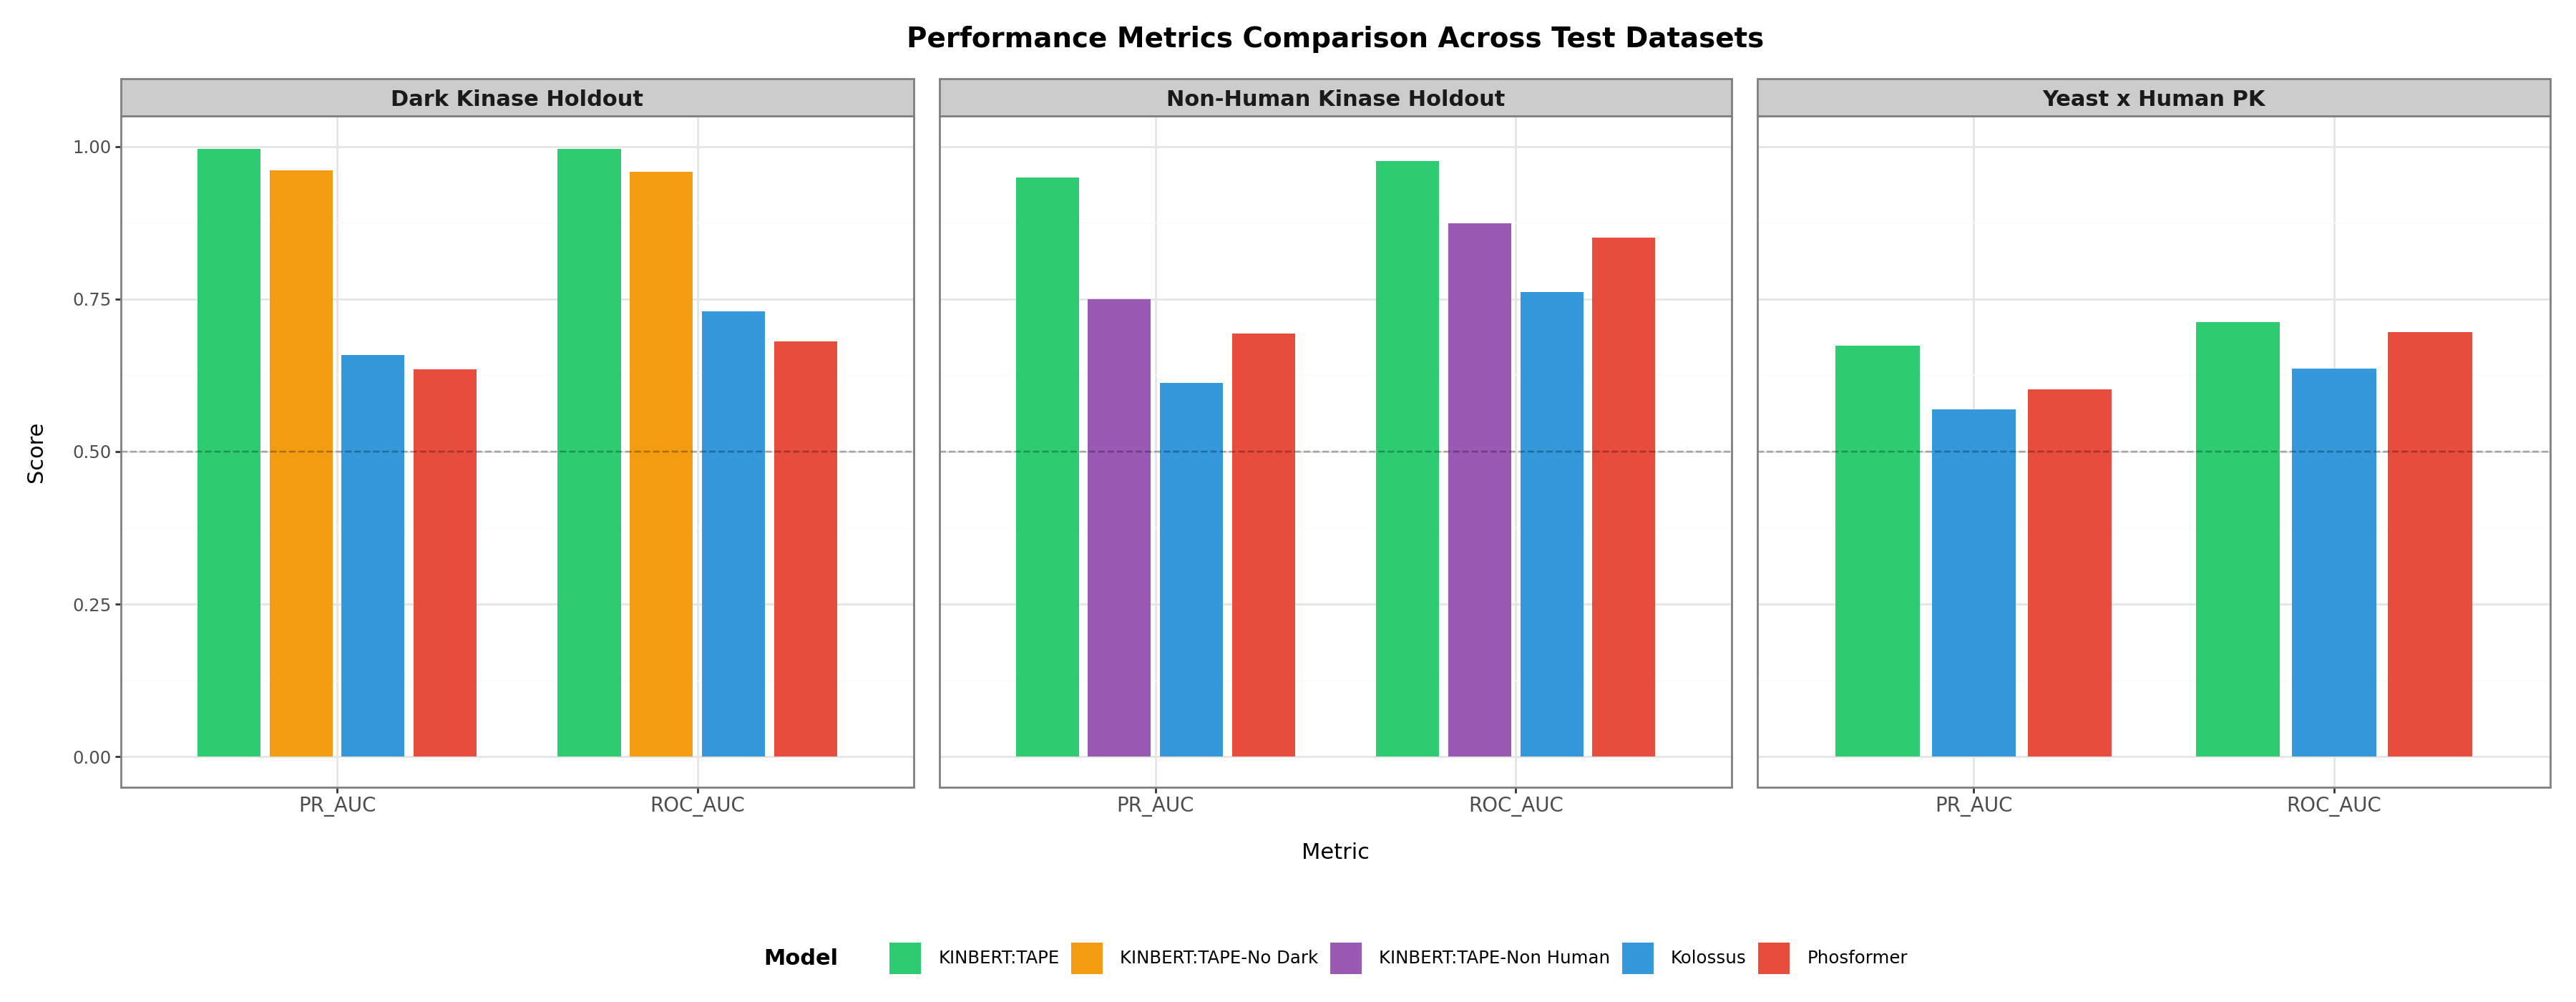

In [46]:
p_bar

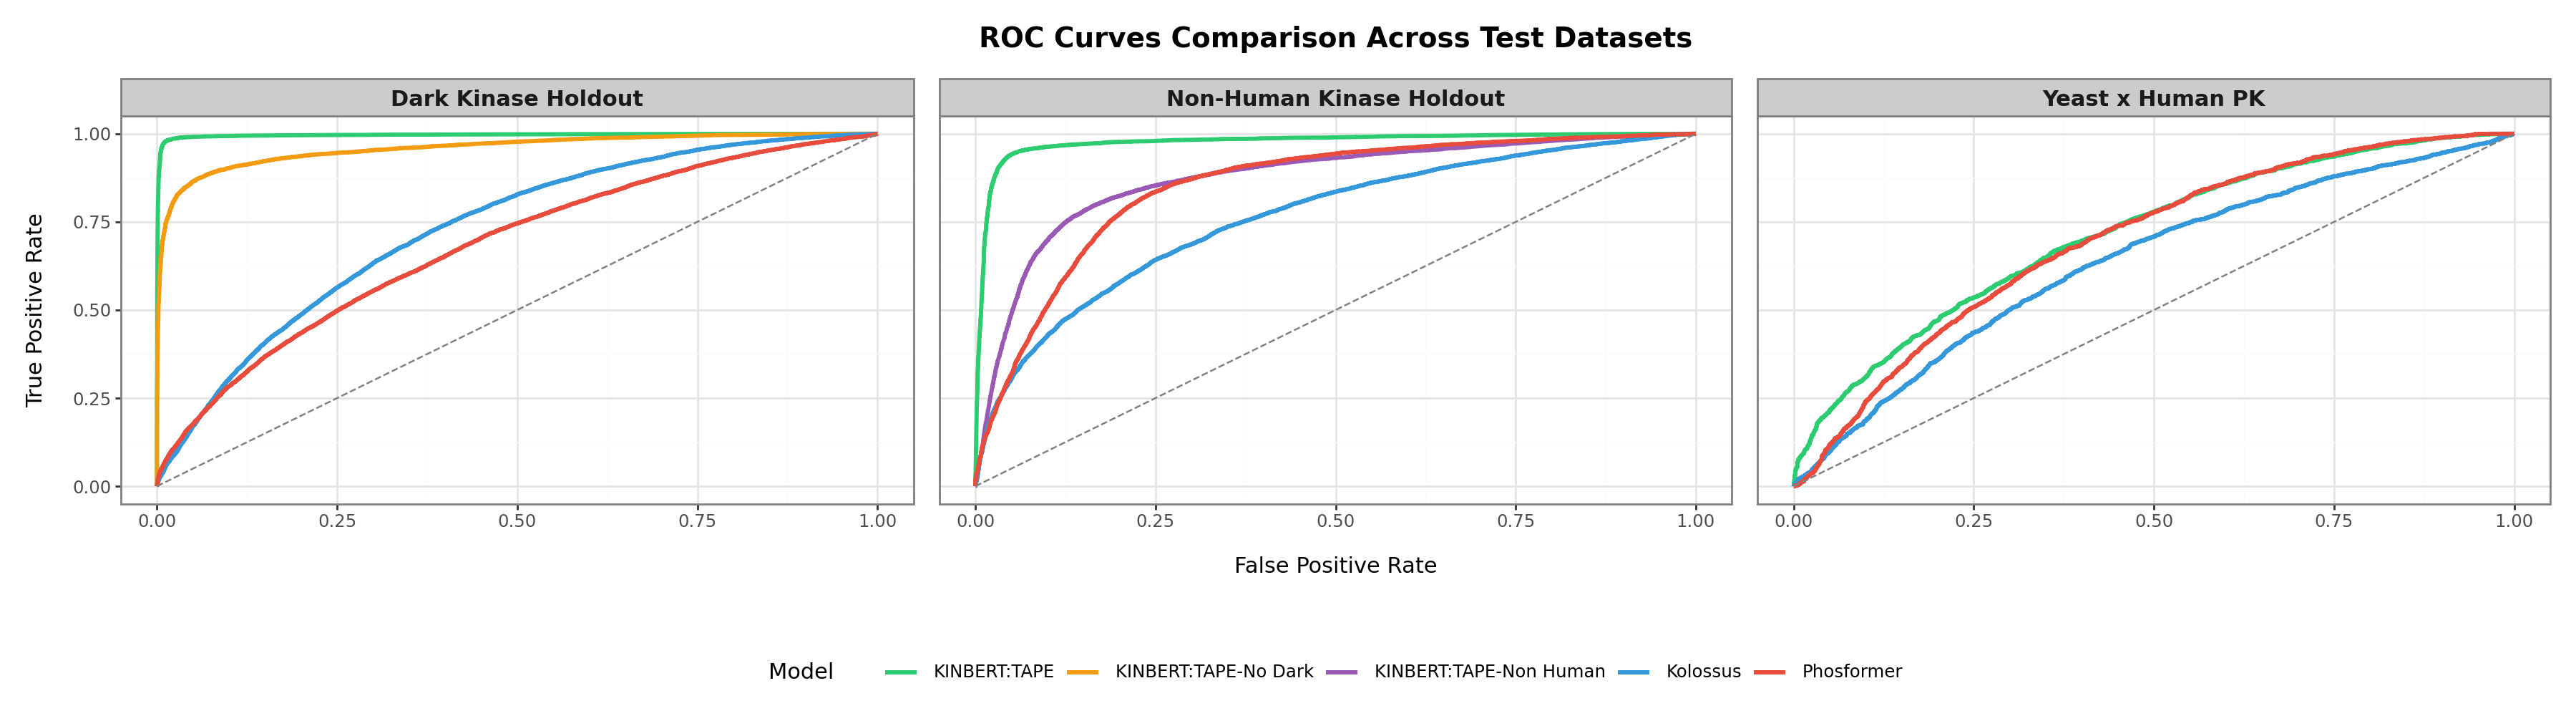

In [47]:
p_roc

In [48]:
out_df = (combined_metrics.loc[:,['Model','Test_Dataset','ROC_AUC','PR_AUC']].set_index(["Test_Dataset", "Model"])[["ROC_AUC", "PR_AUC"]]
    .unstack("Model")          # Model becomes column level
    .sort_index(axis=1, level=0))
out_df = out_df.fillna('')
latex_str = out_df.to_latex(
    multicolumn=True,
    multicolumn_format='c',
    float_format="%.3f",
    index_names=False,
    bold_rows=False,
    escape=False
)
print(latex_str)

\begin{tabular}{lrllrrrllrr}
\toprule
 & \multicolumn{5}{c}{PR_AUC} & \multicolumn{5}{c}{ROC_AUC} \\
Model & KINBERT:TAPE & KINBERT:TAPE-No Dark & KINBERT:TAPE-Non Human & Kolossus & Phosformer & KINBERT:TAPE & KINBERT:TAPE-No Dark & KINBERT:TAPE-Non Human & Kolossus & Phosformer \\
\midrule
Dark Kinase Holdout & 0.996 & 0.961 &  & 0.658 & 0.635 & 0.996 & 0.959 &  & 0.730 & 0.681 \\
Non-Human Kinase Holdout & 0.949 &  & 0.750 & 0.612 & 0.693 & 0.976 &  & 0.874 & 0.762 & 0.851 \\
Yeast x Human PK & 0.674 &  &  & 0.569 & 0.602 & 0.713 &  &  & 0.636 & 0.695 \\
\bottomrule
\end{tabular}



In [49]:
# Display plots
p_bar.save('./eval_figs/benchmark_generalizability_bar.png')
p_bar.save('./eval_figs/benchmark_generalizability_bar.pdf')

p_roc.save('./eval_figs/benchmark_generalizability_roc.png')
p_roc.save('./eval_figs/benchmark_generalizability_roc.pdf')

## Thesis Summary Figure Output

In [1]:
import pandas as pd
from plotnine import *

# =============================================================================
# CONFIGURATION: Customize subplot order and titles here
# =============================================================================
subplot_order = ['DB + LYSATE Test','Phosformer Test','Dark Kinase Holdout','Non-Human Kinase Holdout']
subplot_titles = {'DB + LYSATE Test':'KINBERT Test',
                  'Phosformer Test':'Phosformer Test',
                  'Dark Kinase Holdout':'Dark Kinase',
                  'Non-Human Kinase Holdout':'Non-Human'}

# =============================================================================
print("="*80)
print(f"GENERATING COMBINED PLOTS FROM {len(thesis_pre_data)} BENCHMARKS")
print("="*80)

# Combine all data
all_metrics = []
all_roc = []
for data in thesis_pre_data:
    m = data['metrics'].copy()
    m['Test_Dataset'] = data['test_name']
    m['Benchmark_ID'] = data['benchmark_id']
    all_metrics.append(m)
    
    if data['roc'] is not None:
        r = data['roc'].copy()
        r['Test_Dataset'] = data['test_name']
        all_roc.append(r)

combined_metrics = pd.concat(all_metrics, ignore_index=True)
combined_roc = pd.concat(all_roc) if all_roc else None

print(f"\n✓ Combined data from {len(thesis_pre_data)} benchmarks")
print(f"  Test datasets: {combined_metrics['Test_Dataset'].unique()}")
print(f"  Models: {combined_metrics['Model'].unique()}")

# =============================================================================
# HELPER: Apply subplot order and custom titles
# =============================================================================
def apply_subplot_config(df, col='Test_Dataset', order=None, titles=None):
    """Apply custom ordering and title renaming to a facet column."""
    if titles:
        df = df.copy()
        df[col] = df[col].map(lambda x: titles.get(x, x))
        # Update order to use new titles if order was specified
        if order:
            order = [titles.get(o, o) for o in order]
    if order:
        df[col] = pd.Categorical(df[col], categories=order, ordered=True)
    return df, order

# =============================================================================
# BARPLOT: ROC_AUC and PR_AUC
# =============================================================================
print("\nCreating barplot...")

df_long = combined_metrics[['Model','Accuracy', 'ROC_AUC', 'PR_AUC', 'Test_Dataset']].melt(
    id_vars=['Model', 'Test_Dataset'],
    var_name='Metric',
    value_name='Score'
)

models = df_long['Model'].unique()
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6', 
          '#1ABC9C', '#E91E63', '#FF5722', '#00BCD4', '#8BC34A']
model_colors = {m: colors[i % len(colors)] for i, m in enumerate(models)}

df_long, bar_order = apply_subplot_config(df_long, order=subplot_order, titles=subplot_titles)

p_bar = (
    ggplot(df_long, aes(x='Metric', y='Score', fill='Model'))
    + geom_bar(stat='identity', position=position_dodge(0.8), width=0.7)
    + facet_wrap('~Test_Dataset', ncol=4)
    + theme_bw()
    + theme(
        axis_text_x=element_text(rotation=0, hjust=0.5, size=13),
        axis_text_y=element_text(size=12),
        axis_title_x=element_text(size=14, face='bold'),
        axis_title_y=element_text(size=14, face='bold'),
        figure_size=(14, 5),
        legend_position='bottom',
        legend_title=element_text(size=13, face='bold'),
        legend_text=element_text(size=12),
        strip_text=element_text(size=14, face='bold'),
        plot_title=element_text(size=16, face='bold')
    )
    + labs(
        title='Performance Metrics Comparison Across Test Datasets',
        x='Metric',
        y='Score',
        fill='Model'
    )
    + scale_fill_manual(values=model_colors)
    + geom_hline(yintercept=0.5, linetype='dashed', alpha=0.3)
    + scale_y_continuous(limits=(0, 1))
)

if combined_roc is not None:
    p_roc = (
        ggplot(combined_roc, aes(x='FPR', y='TPR', color='Model'))
        + geom_line(size=1.2)
        + facet_wrap('~Test_Dataset', ncol=4)
        + geom_line(
            aes(x='FPR', y='FPR'),
            color='gray',
            linetype='dashed',
            data=pd.DataFrame({'FPR': [0, 1]}),
            inherit_aes=False
        )
        + theme_bw()
        + theme(
            axis_text_x=element_text(size=12),
            axis_text_y=element_text(size=12),
            axis_title_x=element_text(size=14, face='bold'),
            axis_title_y=element_text(size=14, face='bold'),
            figure_size=(14, 4),
            legend_position='bottom',
            legend_title=element_text(size=13, face='bold'),
            legend_text=element_text(size=12),
            strip_text=element_text(size=14, face='bold'),
            plot_title=element_text(size=16, face='bold')
        )
        + labs(
            title='ROC Curves Comparison Across Test Datasets',
            x='False Positive Rate',
            y='True Positive Rate',
            color='Model'
        )
        + scale_color_manual(values=model_colors)
    )

# =============================================================================
# SUMMARY
# =============================================================================
print("\n" + "="*80)
print("SUMMARY")
print("="*80)
summary = df_long.groupby(['Test_Dataset', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by test dataset:")
print(summary)
model_summary = df_long.groupby(['Model', 'Metric'])['Score'].mean().unstack().round(3)
print("\nMean scores by model (averaged across datasets):")
print(model_summary.sort_values('ROC_AUC', ascending=False))
print("\n" + "="*80)
print("COMPLETE!")
print("="*80)

NameError: name 'thesis_pre_data' is not defined

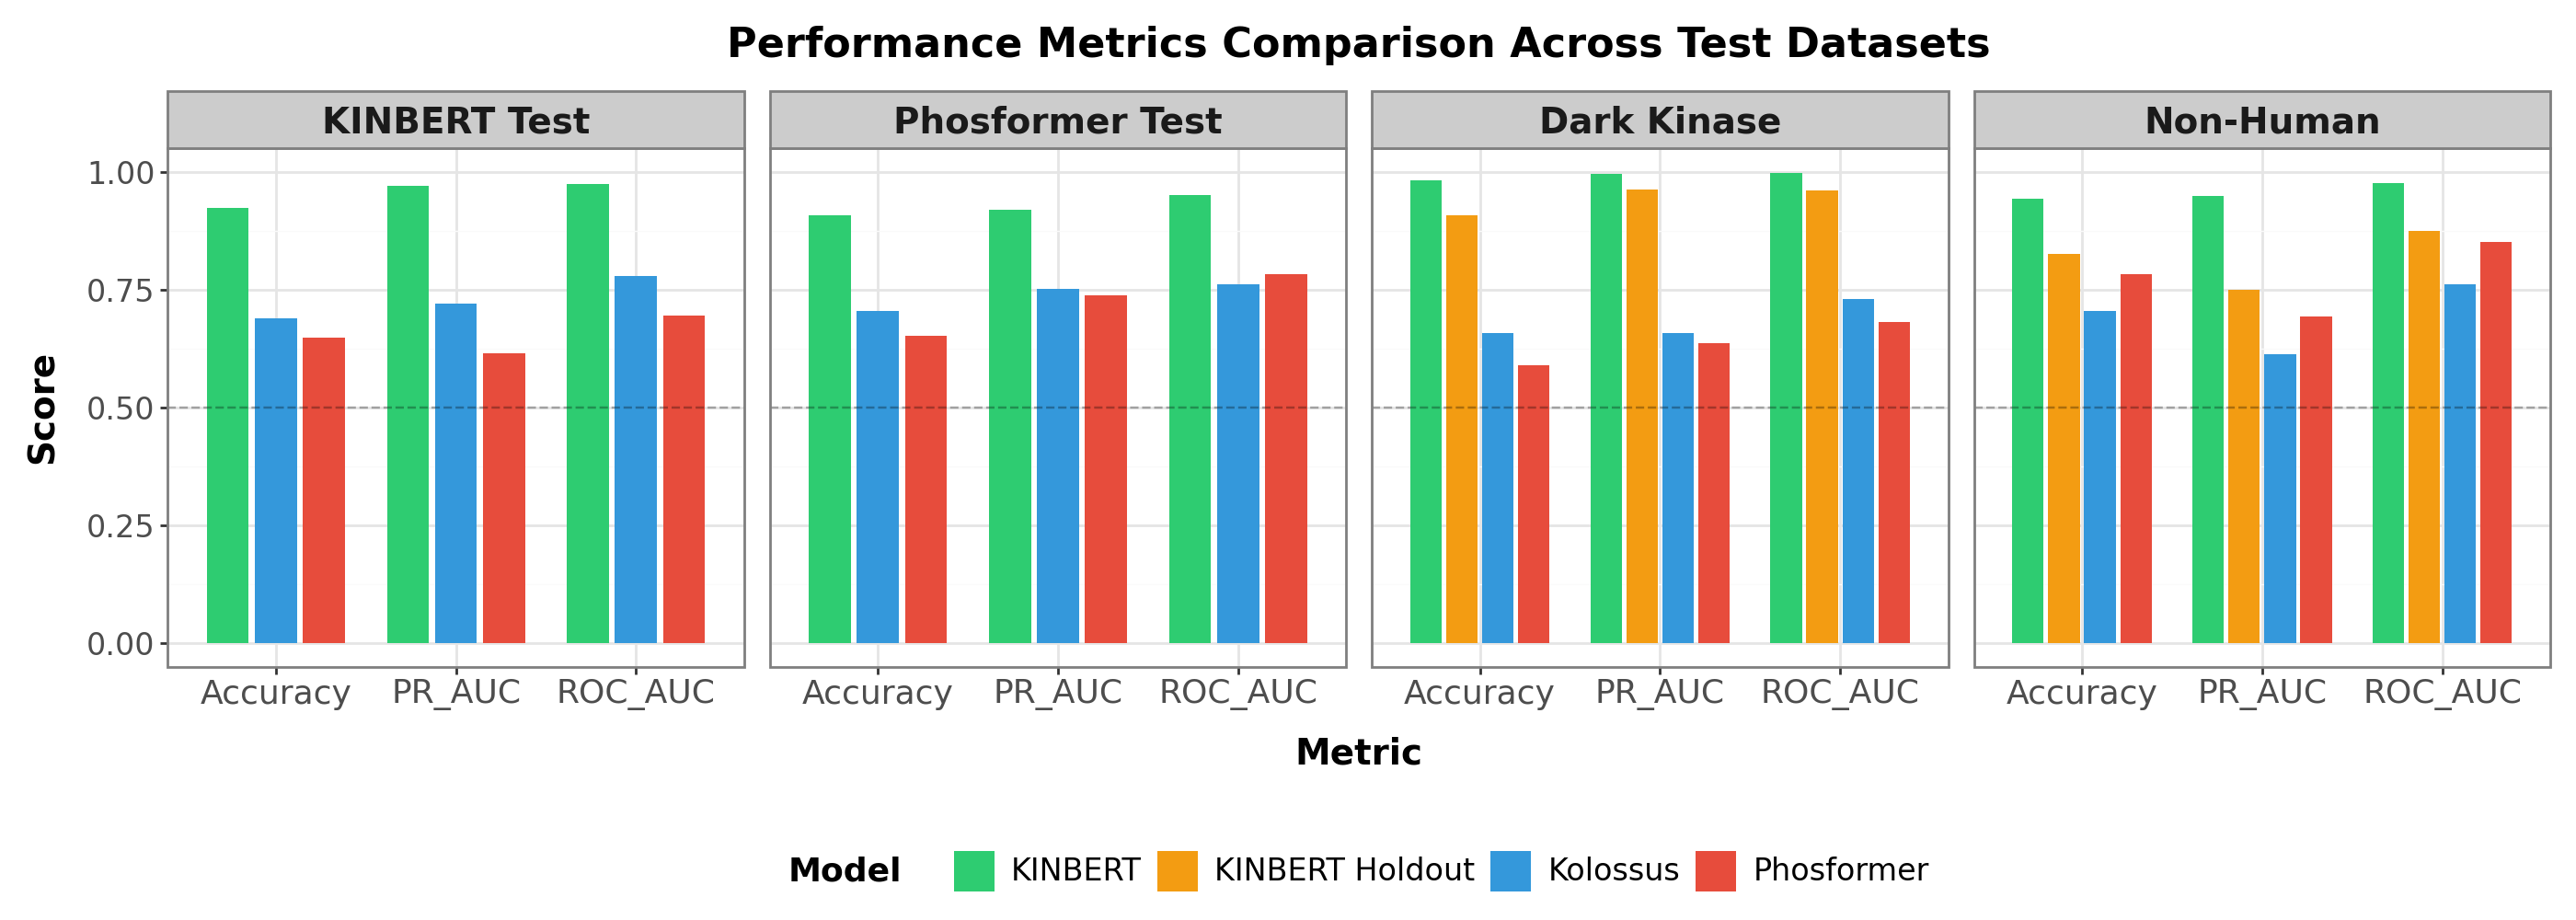

In [173]:
p_bar

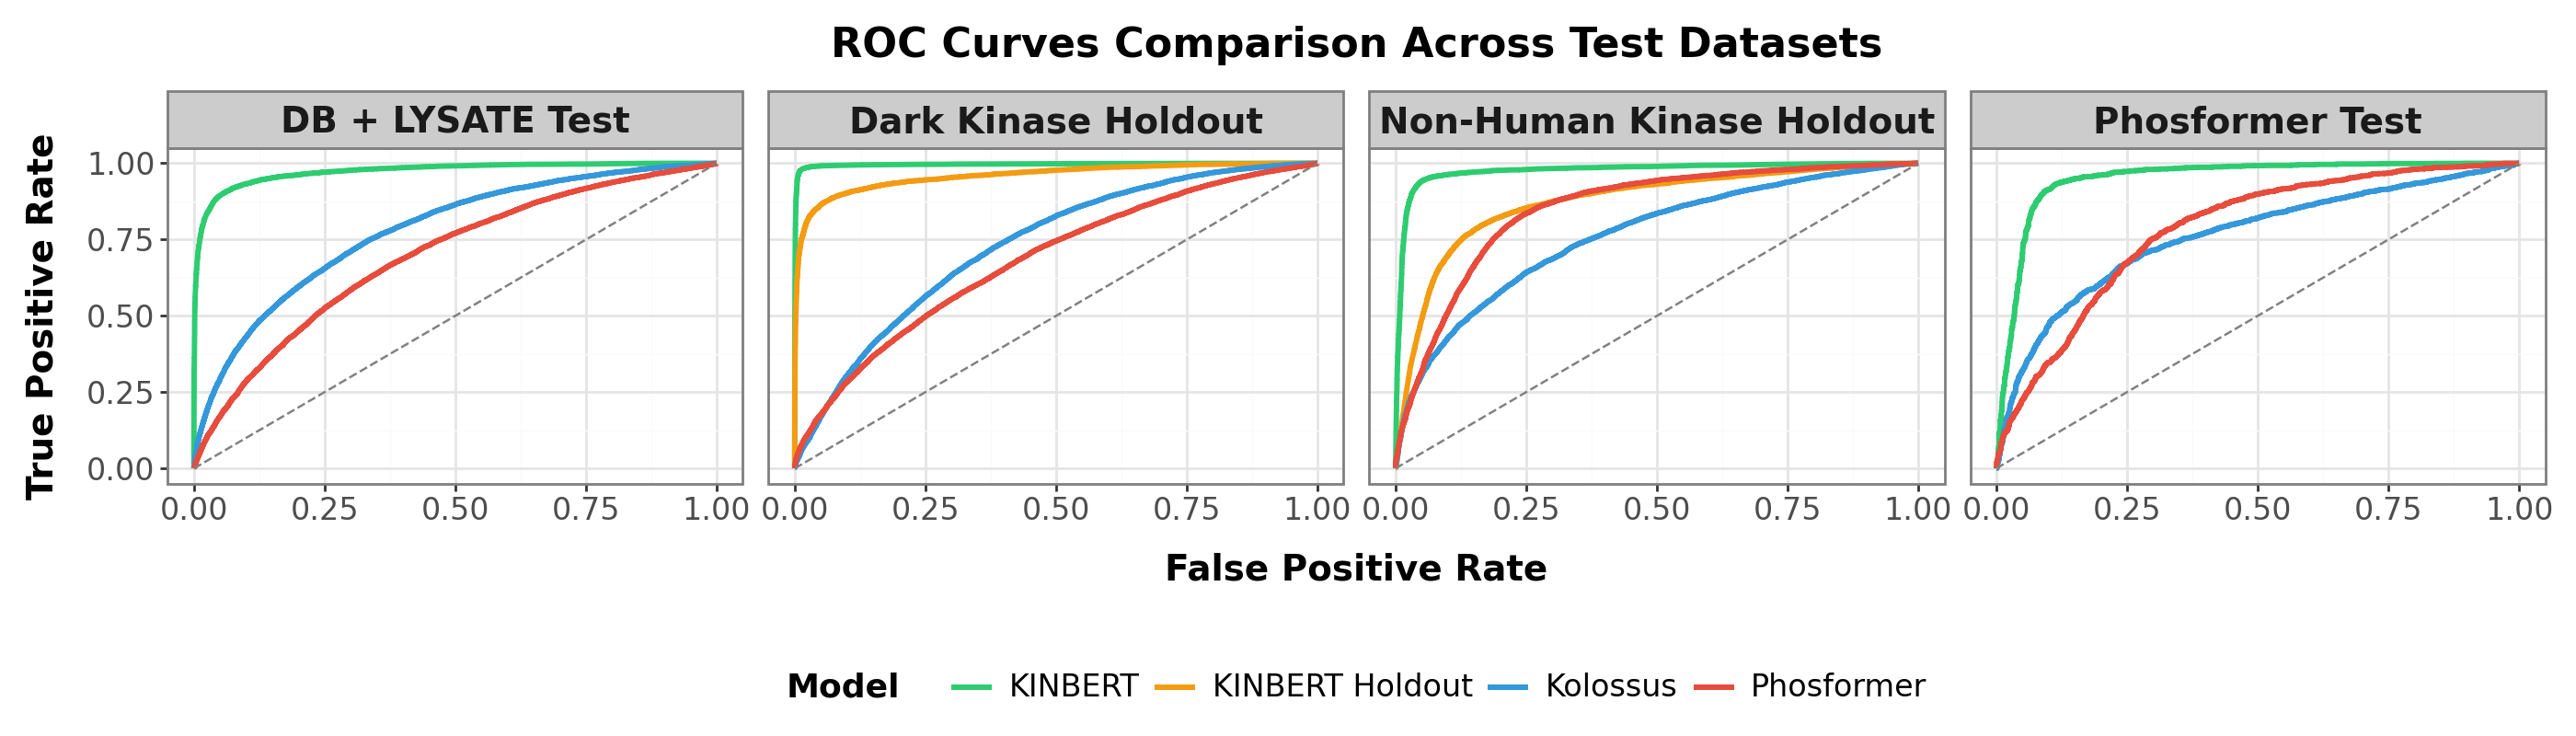

In [174]:
p_roc

In [175]:
p_bar.save('./eval_figs/kinbert_performance_bar_thesis_pre.png')

In [ ]:
p_bar.save('./eval_figs/kinbert_performance_bar_thesis_pre.pdf')

In [176]:
p_roc.save('./eval_figs/kinbert_performance_roc_thesis_pre.png')

In [ ]:
p_roc.save('./eval_figs/kinbert_performance_roc_thesis_pre.pdf')